<div style="background:#2f7d58;color:white;padding:22px 26px;border-radius:12px;">
<h1 style="margin:0;color:white;">Project · Feature Engineering</h1>
<h2 style="margin:8px 0 0 0;color:white;font-weight:500;">Speed Dating Experiment — building the modelling-ready feature table</h2>
</div>

**Course:** Recommender Systems — Master Applied Data Science and AI
**Project:** A reciprocal recommender system for speed dating
**Authors:** Barnard Alison · Kohler Andrin · Tabalae Petronela · Sever Alin (HSLU)
**Input:** `Data/Speed_Dating_Data.csv` (Latin-1) · **Previous step:** `01_Speed_Dating_EDA.ipynb`
**Code:** every function used here lives in `sd_features.py` — this notebook narrates and verifies it

> **How to run.** Python 3.11 with `pip install -r requirements.txt`. Open from the **repository
> root**, so that `sd_features.py` is importable and the data path resolves; run top to bottom.
> Deterministic given `SEED = 42`, and it finishes in well under a minute. Read
> `01_Speed_Dating_EDA.ipynb` first — every design decision here follows from a measurement made
> there. Running this notebook **rewrites** `Data/features/`.

## What this notebook produces

**Running this notebook is what creates the feature files.** `sd_features.py` is a library that is
*imported*, never executed: `python sd_features.py` does nothing on its own, because the module only
defines functions. The two CSV files below are written by **Section 14**, the last step of this
notebook, and both are **committed to the repository**. The modelling and evaluation notebooks can
therefore load them straight from a fresh clone: nobody downstream needs to run this notebook. Run
it again only when a feature definition changes — that overwrites the exported files, which should
then be committed in the same change.

| Artefact | What it is |
|---|---|
| `Data/features/speed_dating_features.csv` | **8,368 rows × 102 columns** — one row per *directed* encounter, raw (unscaled) engineered features |
| `Data/features/feature_dictionary.csv` | Every column: block, definition, source, documented range, NaN fraction, in-default-feature-set flag |
| `sd_features.py` | The importable module (already in the repo, not produced here) — `build_features`, `fit_preprocessor`, `add_behavioural_features` |

## What this notebook does *not* do

It stops at the features. **Model training** (baseline Z, X₁ cluster-based, X₂ factorization
machine) and **evaluation** (the 21-fold leave-one-wave-out loop, NDCG@3 / Precision@3 / MRR /
Coverage@3) are the next people's work. Section 15 is the hand-off contract they need — it is
written for someone who has *not* read the EDA.

> **The one thing to carry away if you read nothing else.** The exported features are
> **deliberately unscaled**. Scaling, one-hot encoding and imputation happen *inside* your CV fold
> via `fit_preprocessor(train)`, because a scaler fitted on the whole table has already seen the
> held-out wave. Section 12 shows this working; Section 15 shows the four lines you need.

## 1. Setup

Same libraries and the same seed as the EDA. The one addition is `sd_features`, the project module
that holds the actual feature logic — so that this notebook, the modelling notebook and the
evaluation notebook all build features from **one** definition instead of three copies that drift
apart.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import sd_features as sf          # the project module -- all feature logic lives there

SEED = sf.SEED
rng = np.random.default_rng(SEED)

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

GREEN, RED, LIGHT = "#2f7d58", "#c44e34", "#7bb59a"

print("NumPy :", np.__version__)
print("pandas:", pd.__version__)
print("module:", Path(sf.__file__).name)

NumPy : 1.26.4
pandas: 3.0.5
module: sd_features.py


## 2. What this notebook inherits from the EDA

Feature engineering here is not a free design exercise. Five findings from `01_Speed_Dating_EDA.ipynb`
constrain it, and every one of them was *measured*, not assumed. They are restated here because the
people who consume this table will not have read that notebook.

| # | Constraint | Evidence (EDA section) | What it forces here |
|---|---|---|---|
| 1 | **Features must be strictly pre-date** | §13 — `report.qmd`, proposal slide 5 and the data key's own leakage note all agree | The in-date scorecard (`attr…shar`, `like`, `prob`), every `_o` event rating, `dec_o` as an input, and all `_s`/`_2`/`_3` surveys are banned. Section 10 enforces this in code |
| 2 | **Leave-one-wave-out CV is a *total* cold start** | §15 — 0 of 551 held-out participants, and 0 held-out partners, have any training history, in **all 21 folds** | Person-level behavioural features (`desirability`, `selectivity`, …) are a constant at test time. They are not in the feature table. Section 11 |
| 3 | **`attr1_1…shar1_1` needs no wave 6–9 rescale** | §12 — all 21 waves already sum to ≈100; waves 6–9 were pre-converted, and their decimals invert exactly to integer 1–10 answers | We still normalise to shares, but for a different reason: the per-wave totals run **90 to 148**. Section 6 |
| 4 | **The compatibility gap needs a pre-date stand-in** | §15.4 — the partner's *observed* ratings are in-date, and absent for a cold partner | Built against the partner's `3_1` **self-ratings** instead. Five attributes, not six: there is no `shar3_1`. Sections 7 and 9 |
| 5 | **Clip before scaling; fit scalers on training waves only** | §14.1 — 617 cells across 25 columns fall outside 1–10 (`gaming` reaches 14, `reading` 13) | Clipping happens once, in `build_person_table`. Everything *fitted* happens inside the caller's fold. Sections 3 and 12 |

### Three tempting alternatives, and why they fail

Those constraints rule out three designs that look perfectly reasonable on first reading — so much
so that each one is the obvious thing to reach for. If you are wondering why this notebook does not
simply do the straightforward thing, this is the answer:

| The obvious approach | Why it does not work here |
|---|---|
| Measure compatibility by comparing what someone *says* they want against **the ratings their partner actually received** | Those ratings are filled in *during* the date, so they fail constraint 1 — and for a partner nobody has met yet they do not exist in the training data either. Section 9 compares against the partner's signup **self-ratings** instead |
| Give the model **how often a person says yes, and how often others say yes to them** | These are by far the strongest pre-date signals in the dataset (\|r\| ≈ 0.40 and 0.36), which is exactly why their absence is surprising. Constraint 2 reduces them to one constant value on every test row. Section 11 demonstrates this rather than asserting it |
| Rescale the stated-preference block for **waves 6–9** before using it | It was already rescaled before the file was published (constraint 3). Normalising to shares is still the right move, but for a different reason — the totals run 90 to 148 — and it does not make the two question formats comparable (Section 6) |

## 3. The person table — one row per participant

The CSV is one row per *date*, so a participant appears 5–22 times. Every signup answer is
therefore repeated, and averaging anything over date rows would silently weight people by how many
dates they had. We de-duplicate on `iid` first and keep the signup survey only.

**Clipping happens here, once**, so every feature built later inherits clean inputs: ratings and
interests to [1, 10], `imprace`/`imprelig` to [1, 10], the two frequency ordinals to [1, 7]. The
EDA measured why (§14.1): `gaming` reaches 14 and `reading` 13, which would stretch a min–max
scaler across the whole column.

Four pre-date columns are excluded on missingness rather than kept and imputed (EDA §7.1):
`expnum` (77% missing), `mn_sat` (63%), `tuition` (58%), `income` (49%). The missingness is not
random — income and SAT are blank for anyone who studied abroad — so an imputed value would carry
its own bias into the fairness analysis.

In [2]:
raw = sf.load_raw()
person = sf.build_person_table(raw)

print(f"Raw file:     {raw.shape[0]:,} date rows x {raw.shape[1]} columns")
print(f"Person table: {person.shape[0]} participants x {person.shape[1]} signup columns")
display(person.head())

# How complete is each block? This is the imputation budget, known up front.
BLOCKS = {
    "profile (10 cols)":      sf.PROFILE_NUM + sf.PROFILE_CAT,
    "interests (17)":         sf.INTERESTS,
    "self-ratings 3_1 (5)":   sf.SELFRATE,
    "stated prefs 1_1 (6)":   sf.PREF,
}
coverage = pd.DataFrame({
    "n_cols": {k: len(v) for k, v in BLOCKS.items()},
    "people_with_complete_block": {k: int(person[v].notna().all(axis=1).sum()) for k, v in BLOCKS.items()},
    "people_missing_something":   {k: int(person[v].isna().any(axis=1).sum()) for k, v in BLOCKS.items()},
})
coverage["share_complete"] = coverage["people_with_complete_block"] / len(person)
display(coverage)

Raw file:     8,378 date rows x 195 columns
Person table: 551 participants x 38 signup columns


,age,imprace,imprelig,exphappy,go_out,date,race,field_cd,career_c,goal,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,selfrate_attr,selfrate_sinc,selfrate_intel,selfrate_fun,selfrate_amb,pref_attr,pref_sinc,pref_intel,pref_fun,pref_amb,pref_shar
iid,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,21.000,2.000,4.000,3.000,1.000,7.000,4.000,1.000,NaN,2.000,9.000,2.000,8.000,9.000,1.000,1.000,5.000,1.000,5.000,6.000,9.000,1.000,10.000,10.000,9.000,8.000,1.000,6.000,8.000,8.000,8.000,7.000,0.150,0.200,0.200,0.150,0.150,0.150
2,24.000,2.000,5.000,4.000,1.000,5.000,2.000,1.000,NaN,1.000,3.000,2.000,7.000,10.000,8.000,6.000,3.000,5.000,8.000,10.000,1.000,9.000,8.000,7.000,8.000,3.000,1.000,7.000,5.000,8.000,10.000,3.000,0.450,0.050,0.250,0.200,0.000,0.050
3,25.000,8.000,4.000,4.000,1.000,3.000,2.000,2.000,NaN,6.000,3.000,8.000,7.000,8.000,5.000,5.000,8.000,4.000,5.000,7.000,8.000,7.000,7.000,7.000,5.000,8.000,7.000,8.000,9.000,9.000,8.000,8.000,0.350,0.100,0.350,0.100,0.100,0.000
4,23.000,1.000,1.000,1.000,1.000,5.000,2.000,1.000,1.000,1.000,1.000,1.000,6.000,7.000,6.000,7.000,7.000,5.000,7.000,7.000,7.000,9.000,7.000,8.000,7.000,1.000,8.000,7.000,8.000,7.000,9.000,8.000,0.200,0.200,0.200,0.200,0.100,0.100
5,21.000,8.000,1.000,7.000,1.000,4.000,2.000,1.000,1.000,2.000,7.000,4.000,7.000,7.000,6.000,8.000,6.000,6.000,8.000,6.000,8.000,6.000,6.000,3.000,7.000,8.000,3.000,6.000,3.000,10.000,6.000,8.000,0.200,0.050,0.250,0.250,0.100,0.150


,n_cols,people_with_complete_block,people_missing_something,share_complete
profile (10 cols),10,536,15,0.973
interests (17),17,544,7,0.987
self-ratings 3_1 (5),5,542,9,0.984
stated prefs 1_1 (6),6,541,10,0.982


**What to notice:** every block is 97-99% complete at participant level, so no block has to be
dropped and no aggressive imputation is needed. The gaps are a handful of people who skipped part
of the signup survey, and they stay as `NaN` all the way to the export — filling them is the
*caller's* decision, made inside the fold (Section 12), not ours.

## 4. The directed pair table — keys and labels

One row of the output is **one directed encounter**: `iid` meeting `pid`. Every meeting appears
twice, once from each side, and the mirror of `(a, b)` is the separate row `(b, a)`. We keep it
that way rather than collapsing to one row per pair, because the project models
**P(A says yes to B)** directionally and combines the two directions afterwards — the deck's
harmonic-mean reciprocal score needs both.

Three labels are exported so the modelling team can pick their target without touching this
notebook:

| Column | Role |
|---|---|
| `dec` | This participant's yes/no — the **directional training target** |
| `dec_o` | The partner's yes/no about them, i.e. the reverse direction's label. **Label only** — using it as an input is the most tempting leak in the file |
| `match` | 1 iff both said yes — the **relevance label** for ranking metrics |

Rows with no `pid` are dropped: 10 of 8,378. They name no partner, so no dyadic feature exists for
them, and they have no mirror row either.

We assert the structural facts rather than trust them, because everything downstream — the
wave-level CV split, the reciprocal aggregation, and the candidate sets the evaluation will rank —
rests on them.

In [3]:
features = sf.build_features(raw)

print(f"Directed encounters kept: {len(features):,} of {len(raw):,} "
      f"({raw['pid'].isna().sum()} rows have no `pid` and are dropped)")
print(f"Feature table: {features.shape[0]:,} rows x {features.shape[1]} columns")

# Structural facts the whole project rests on -- verified, not assumed.
gender_of = raw.drop_duplicates("iid").set_index("iid")["gender"]
opposite_sex = (features["gender"] != features["pid"].map(gender_of)).all()

pair_keys = set(zip(features["iid"], features["pid"]))
mirrors_present = sum((b, a) in pair_keys for a, b in pair_keys)

# Did everyone meet everyone? A person's candidate set is the opposite-sex roster of their wave,
# so this decides whether the evaluation needs negative sampling or not.
wave_of = raw.drop_duplicates("iid").set_index("iid")["wave"]
roster_size = {i: int(((wave_of == wave_of[i]) & (gender_of != gender_of[i])).sum())
               for i in wave_of.index}
met = features.groupby("iid")["pid"].nunique()
full_roster = sum(1 for i, n in roster_size.items() if met.get(i, 0) == n)

print()
print(f"All encounters are opposite-sex:                {opposite_sex}")
print(f"Rows whose mirror row (b, a) is present:        {mirrors_present:,} of {len(features):,}")
print(f"`match` == `dec` AND `dec_o` on every row:      "
      f"{bool(((features['dec'] & features['dec_o']) == features['match']).all())}")
print(f"Every encounter stays inside one wave:          "
      f"{bool((features['wave'] == features['pid'].map(raw.drop_duplicates('iid').set_index('iid')['wave'])).all())}")
print(f"Met their wave's ENTIRE opposite-sex roster:    {full_roster} of {len(roster_size)} people")

display(features[sf.KEYS + sf.LABELS].head())

Directed encounters kept: 8,368 of 8,378 (10 rows have no `pid` and are dropped)
Feature table: 8,368 rows x 102 columns

All encounters are opposite-sex:                True
Rows whose mirror row (b, a) is present:        8,368 of 8,368
`match` == `dec` AND `dec_o` on every row:      True


Every encounter stays inside one wave:          True
Met their wave's ENTIRE opposite-sex roster:    551 of 551 people


,iid,pid,wave,gender,order,dec,dec_o,match
0,1,11,1,0,4,1,0,0
1,1,12,1,0,3,1,0,0
2,1,13,1,0,10,1,1,1
3,1,14,1,0,5,1,1,1
4,1,15,1,0,7,1,1,1


**What to notice:** all five checks pass. The last one matters for the evaluation as much as for
the features: **every participant met their wave's entire opposite-sex roster**, so each person's
candidate set is fully observed and no negative sampling is required — an unusually clean property
for an offline recommender evaluation. The mirror completeness (8,368 of 8,368) is what makes
the reciprocal half of the feature set possible — for every direction A→B we build, the direction
B→A exists as its own row with the mirrored features. Section 13 uses exactly this to catch a
swapped join.

One implementation detail worth flagging for whoever maintains this. The person table is attached
twice — `join(person, on="iid")` and `join(person.add_suffix("_p"), on="pid")` — and the key
columns must be selected **before** the join. The raw frame already contains `age`, `race`,
`field_cd`…, so joining onto the full frame raises `columns overlap but no suffix specified`.

## 5. Block A — the profile features, both sides

The signup demographics, attached once for the decider (no suffix) and once for the partner
(`_p`). The data key supplies four of them ready-made on the row (`age_o`, `race_o`, `int_corr`,
`samerace`) but the rest — `field_cd`, `goal`, `go_out`, `date`, `career_c` — have no `_o` version
and need the `pid` map-join.

Two coding traps that a reader of the feature table cannot see, and which are therefore written
into the data dictionary:

- **`go_out` and `date` are reverse-coded**: 1 = several times a week … 7 = almost never. A *high*
  value means someone who rarely goes out. The derived `go_out_diff` is therefore a lifestyle
  *mismatch*, not a level.
- **`race`, `field_cd`, `career_c`, `goal` are codes, not magnitudes.** The numeric distance
  between "law" (1) and "medicine" (8) is meaningless. They are one-hot encoded in Section 12 and
  must never be scaled.

In [4]:
profile_cols = sf.PROFILE_NUM + sf.PROFILE_CAT
side_by_side = pd.DataFrame({
    "decider_column": profile_cols,
    "partner_column": [f"{c}_p" for c in profile_cols],
    "kind": (["numeric"] * len(sf.PROFILE_NUM)) + (["categorical code"] * len(sf.PROFILE_CAT)),
    "nan_frac_self": [features[c].isna().mean() for c in profile_cols],
    "nan_frac_partner": [features[f"{c}_p"].isna().mean() for c in profile_cols],
})
display(side_by_side)

print("Categorical levels (fixed from the data key, NOT learned from the data -- see Section 12):")
for c, levels in sf.CATEGORY_LEVELS.items():
    observed = sorted(int(v) for v in features[c].dropna().unique())
    print(f"  {c:<9} documented {len(levels):>2} levels, observed {len(observed):>2}: {observed}")

,decider_column,partner_column,kind,nan_frac_self,nan_frac_partner
0,age,age_p,numeric,0.011,0.011
1,imprace,imprace_p,numeric,0.009,0.009
2,imprelig,imprelig_p,numeric,0.009,0.009
3,exphappy,exphappy_p,numeric,0.012,0.012
4,go_out,go_out_p,numeric,0.009,0.009
5,date,date_p,numeric,0.012,0.012
6,race,race_p,categorical code,0.008,0.008
7,field_cd,field_cd_p,categorical code,0.010,0.010
8,career_c,career_c_p,categorical code,0.016,0.016
9,goal,goal_p,categorical code,0.009,0.009


Categorical levels (fixed from the data key, NOT learned from the data -- see Section 12):
  race      documented  6 levels, observed  5: [1, 2, 3, 4, 6]
  field_cd  documented 18 levels, observed 18: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
  career_c  documented 17 levels, observed 17: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
  goal      documented  6 levels, observed  6: [1, 2, 3, 4, 5, 6]


**What to notice:** `race` is documented with six codes but only **five** appear — code 5, Native
American, is absent from this file. That is precisely why the one-hot category lists in
`sd_features.py` are hard-coded from the data key instead of inferred: a fold that happens to
contain no Latino participant would otherwise produce a feature matrix with a different number of
columns from every other fold. In a 21-fold loop that is a real bug, and a quiet one.

## 6. Block B — stated preferences, normalised to shares

`attr1_1 … shar1_1` is what each person *says* they want, allocated across the six attributes at
signup. The EDA settled two questions about this block (§12):

1. **The documented wave 6–9 scale problem does not apply here.** All 21 waves already sum to
   ≈100. Waves 6–9 *were* collected on a 1–10 scale, but somebody converted them before publishing
   — they are the only waves whose values are not whole numbers, and those decimals invert exactly
   back to integer 1–10 answers. Nothing to fix.
2. **We normalise anyway**, because the per-wave totals actually run **90 to 148** — a few people
   over- or under-allocated. Dividing each person by their own total makes every row a set of
   shares that sum to 1, which is what the compatibility features in Section 9 need.

The partner's block ships ready-made as `pf_o_*`. We verify it really is the partner's own
`1_1` block rather than trusting the documentation — and then use the map-join version only, so
there is exactly one definition of "the partner's stated preferences" in the project.

In [5]:
pref_cols = sf.PREF
totals = features[pref_cols].sum(axis=1)
complete = features[pref_cols].notna().all(axis=1)

print(f"Rows with a complete preference block: {complete.sum():,} of {len(features):,} "
      f"({complete.mean():.1%})")
print(f"Max deviation from a sum of 1 on those rows: {(totals[complete] - 1).abs().max():.2e}")
print(f"Rows with a PARTIAL block (some weights present, some missing): "
      f"{int((features[pref_cols].notna().any(axis=1) & ~complete).sum())}")

# Verify `pf_o_*` == the partner's own `1_1` block, rather than assuming it.
own = raw.drop_duplicates("iid").set_index("iid")[sf.PREF1_RAW]
joined = raw[["pid"]].join(own.set_axis([f"{c}_j" for c in sf.PF_O_RAW], axis=1), on="pid")
both = raw[sf.PF_O_RAW].notna().all(axis=1) & joined.notna().all(axis=1)
gap = np.abs(raw.loc[both, sf.PF_O_RAW].to_numpy()
             - joined.loc[both, [f"{c}_j" for c in sf.PF_O_RAW]].to_numpy())
print(f"\n`pf_o_*` vs the partner's own `1_1`, compared on {int(both.sum()):,} rows: "
      f"max abs difference {gap.max():.4f}")

display(features[pref_cols + [f"{c}_p" for c in pref_cols[:3]]].describe().T[["mean", "std", "min", "max"]])

Rows with a complete preference block: 8,249 of 8,368 (98.6%)
Max deviation from a sum of 1 on those rows: 2.22e-16
Rows with a PARTIAL block (some weights present, some missing): 0

`pf_o_*` vs the partner's own `1_1`, compared on 8,249 rows: max abs difference 0.0000


,mean,std,min,max
pref_attr,0.224,0.124,0.000,1.000
pref_sinc,0.174,0.070,0.000,0.600
pref_intel,0.203,0.068,0.000,0.500
pref_fun,0.175,0.061,0.000,0.500
pref_amb,0.107,0.060,0.000,0.358
pref_shar,0.118,0.064,0.000,0.300
pref_attr_p,0.224,0.124,0.000,1.000
pref_sinc_p,0.174,0.070,0.000,0.600
pref_intel_p,0.203,0.068,0.000,0.500


**What to notice:** the shares sum to 1 to machine precision, and there are **no partial rows** —
a participant either answered the whole block or none of it, which makes the missingness easy to
reason about (119 rows, all of them people who skipped the question entirely).

`pf_o_*` is confirmed identical to the partner's own block (max difference 0.0000). We still build
the partner side by joining on `pid`, for one reason: a single definition cannot drift. If a future
change alters how preferences are normalised, both sides change together.

## 7. Block C — self-ratings, the pre-date stand-in for "what this person is like"

This is the block that makes a cold-start compatibility feature possible at all.

The proposal defines the compatibility gap as the distance between a person's stated preferences
and *the partner's observed attribute ratings*. Read literally, those ratings are the ones the
partner received **during** the date — which fails the pre-date rule twice over: they are in-date,
and for a partner nobody has met yet they do not exist in the training data either (EDA §15.4).

`attr3_1 … amb3_1` — how each participant rates **themselves** at signup — is the substitute.
Coverage is 542 of 551 participants across all 21 waves, and every value exists before anyone
meets anyone.

**One structural limitation to design around:** the block has **five** attributes, not six. Nobody
self-rates their "shared interests", because that is a property of a pair rather than a person. So
the compatibility dot product is 5-dimensional, and the sixth stated weight (`pref_shar`) is paired
with `int_corr` instead — the natural pre-date proxy for shared interests.

,count,mean,std,min,max,missing_on_partner_side
selfrate_attr,"8,263.000",7.084,1.396,2.000,10.000,0.013
selfrate_sinc,"8,263.000",8.296,1.407,2.000,10.000,0.013
selfrate_intel,"8,263.000",8.404,1.076,3.000,10.000,0.013
selfrate_fun,"8,263.000",7.704,1.564,2.000,10.000,0.013
selfrate_amb,"8,263.000",7.578,1.779,2.000,10.000,0.013


Attributes with a stated weight (1_1):   ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar']
Attributes with a self-rating  (3_1):   ['attr', 'sinc', 'intel', 'fun', 'amb']
-> the compatibility dot product is 5-dimensional; `shar` has no partner and
   is paired with `int_corr` instead (Section 9).


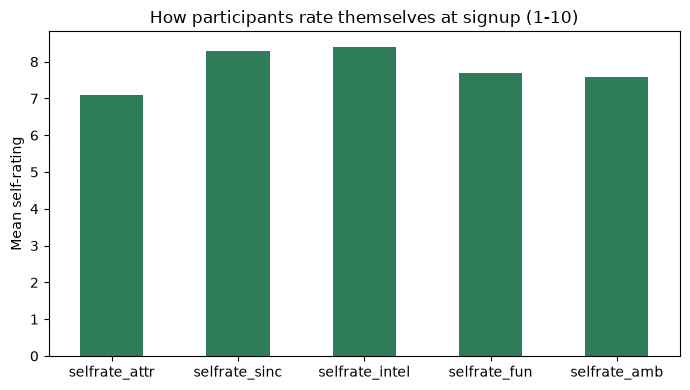

In [6]:
selfrate_cols = sf.SELFRATE
summary = features[selfrate_cols].describe().T[["count", "mean", "std", "min", "max"]]
summary["missing_on_partner_side"] = [features[f"{c}_p"].isna().mean() for c in selfrate_cols]
display(summary)

print(f"Attributes with a stated weight (1_1):   {sf.ATTR6}")
print(f"Attributes with a self-rating  (3_1):   {sf.ATTR5}")
print(f"-> the compatibility dot product is {len(sf.ATTR5)}-dimensional; `shar` has no partner and")
print("   is paired with `int_corr` instead (Section 9).")

fig, ax = plt.subplots(figsize=(7, 4))
features[selfrate_cols].mean().plot(kind="bar", ax=ax, color=GREEN)
ax.set_title("How participants rate themselves at signup (1-10)")
ax.set_xlabel(""); ax.set_ylabel("Mean self-rating")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**What to notice:** the self-ratings are compressed and optimistic — means of 7.1–8.4 against a
scale midpoint of 5.5, and nobody at all rating their own intelligence below 3. That matters for the
compatibility feature: it varies mostly through the *weights* people assign, not through the
attributes they claim. It is a weak signal built from an honest source, which is the trade the
pre-date constraint forces.

## 8. Block D — interests, and two ways to measure shared taste

Each participant rates 17 activities 1–10 at signup. The file also ships `int_corr`, a
pre-computed interest correlation for the pair — but the EDA found it far weaker than its billing
(|r| = 0.02 against `dec`, §11), so it is worth knowing exactly what it is before relying on it.

We recompute the similarity ourselves, two ways (Pearson and cosine over the 17 columns), and
compare. Not to replace `int_corr` — both go in the table — but so the modelling team knows whether
they are three views of one number or three different features.

,count,mean,std,min,max
int_corr,"8,210.000",0.196,0.304,-0.830,0.910
int_sim_pearson,"8,210.000",0.219,0.285,-0.671,0.907
int_sim_cosine,"8,210.000",0.889,0.055,0.571,0.988


,int_corr,int_sim_pearson,int_sim_cosine
int_corr,1.000,0.933,0.582
int_sim_pearson,0.933,1.000,0.638
int_sim_cosine,0.582,0.638,1.000


int_corr vs our Pearson: correlation 0.933, max abs difference 0.805
Rows where `int_corr` is missing but our recomputation succeeds: 0


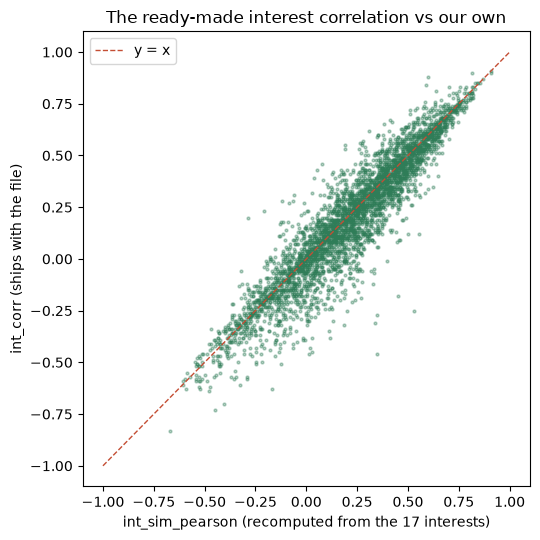

In [7]:
comparison = features[["int_corr", "int_sim_pearson", "int_sim_cosine"]]
display(comparison.describe().T[["count", "mean", "std", "min", "max"]])
display(comparison.corr().round(3))

both_present = features[["int_corr", "int_sim_pearson"]].notna().all(axis=1)
diff = (features.loc[both_present, "int_corr"] - features.loc[both_present, "int_sim_pearson"]).abs()
print(f"int_corr vs our Pearson: correlation {comparison['int_corr'].corr(comparison['int_sim_pearson']):.3f}, "
      f"max abs difference {diff.max():.3f}")

# Can our version repair int_corr's gaps?
recoverable = int((features["int_corr"].isna() & features["int_sim_pearson"].notna()).sum())
print(f"Rows where `int_corr` is missing but our recomputation succeeds: {recoverable}")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(features["int_sim_pearson"], features["int_corr"], s=4, alpha=0.2, color=GREEN)
ax.plot([-1, 1], [-1, 1], color=RED, linestyle="--", linewidth=1, label="y = x")
ax.set_xlabel("int_sim_pearson (recomputed from the 17 interests)")
ax.set_ylabel("int_corr (ships with the file)")
ax.set_title("The ready-made interest correlation vs our own")
ax.legend(); plt.tight_layout(); plt.show()

**What to notice — a small finding with a practical consequence.** `int_corr` and a plain Pearson
correlation over the 17 interest columns agree closely (r = 0.93) but are **not the same number**:
individual rows differ by up to 0.81. Whatever the study authors computed, it is not reproducible
from the 17 published columns alone. Both stay in the table, documented as distinct; a modeller who
assumes they are interchangeable would be wrong.

The second result is the more useful one: **our recomputation repairs exactly zero of `int_corr`'s
gaps.** It is missing on precisely the rows where one side's interest vector is incomplete, so
there is nothing to recover. The 1.9% of rows without an interest similarity stay missing, and the
fold-level imputer deals with them.

## 9. Block E — dyadic and compatibility features

Everything so far describes two people separately. This block describes the **pair**, and it is
where the reciprocal framing enters the feature table.

**Dyadic features** are cheap comparisons of the two profiles:

| Feature | Definition | Note |
|---|---|---|
| `age_diff`, `age_gap` | absolute and **signed** age difference | The signed version is kept on purpose: preference for a younger or older partner is gender-asymmetric, which is exactly what X₁ is built to exploit. `age_diff` alone would erase it |
| `samerace`, `race_importance` | ready-made flag; `imprace × samerace` | The interaction matters more than either part: the EDA measured that people who rate same-race importance ≥7 drop 12–17 points in yes-rate across race lines, while people who rate it ≤3 are flat (§8.1). **No religion analogue is constructible** — the file has `imprelig` but no religion identity column, so `samerelig` does not exist |
| `same_field`, `same_goal`, `same_career` | code equality, `NaN` if either side is missing | `NaN`, not 0: "we do not know their field" is not "their field differs" |
| `go_out_diff`, `date_diff` | absolute difference on the 1–7 frequency ordinals | A lifestyle *mismatch*, given the reverse coding |

**Compatibility features** are the reciprocal half — my stated weights against what the partner
says they *are*, and the mirror image of that:

| Feature | Definition |
|---|---|
| `compat_a2b` | my five preference weights (renormalised over the attributes that have a self-rating) · the partner's self-ratings |
| `compat_b2a` | the partner's weights · my self-ratings — **the direction the deck's reciprocal score needs** |
| `compat_harmonic` | harmonic mean of the two: one symmetric number, ready to rank on |
| `compat_gap_l1` | the same idea as a *distance*: L1 between my weight vector and the partner's self-rating profile as shares |
| `shar_x_intcorr`, `shar_x_intcorr_p` | the sixth stated weight × `int_corr`, one per side |

Both sides of every one of these comes from the signup survey, so all of them exist for a
participant nobody has ever met. That is the whole point.

In [8]:
dyadic_and_compat = sf.FEATURES_DYADIC + sf.FEATURES_COMPAT
audit = pd.DataFrame({
    "non_null": features[dyadic_and_compat].notna().sum(),
    "nan_fraction": features[dyadic_and_compat].isna().mean(),
    "mean": features[dyadic_and_compat].mean(),
    "min": features[dyadic_and_compat].min(),
    "max": features[dyadic_and_compat].max(),
})
display(audit)

,non_null,nan_fraction,mean,min,max
age_diff,8180,0.022,3.658,0.000,32.000
age_gap,8180,0.022,0.000,-32.000,32.000
samerace,8368,0.000,0.396,0.000,1.000
race_importance,8289,0.009,1.637,0.000,10.000
same_field,8204,0.020,0.117,0.000,1.000
same_goal,8210,0.019,0.310,0.000,1.000
same_career,8094,0.033,0.185,0.000,1.000
go_out_diff,8210,0.019,1.123,0.000,6.000
date_diff,8174,0.023,1.613,0.000,6.000
int_corr,8210,0.019,0.196,-0.830,0.910


`compat_a2b` and `compat_b2a` have identical means and ranges in the table above, which is worth
a second look before assuming it is a bug: every encounter appears from both sides, so the *set* of
A→B scores and the *set* of B→A scores are the same numbers in a different order. They differ row
by row — which is all that matters for ranking — and Section 13 verifies exactly that.

Coverage is the first question; **signal** is the second. The EDA already warned that the pre-date
block is weak (|r| ≤ 0.05 against `dec`, §13.2), so this is a sanity check rather than a hunt for
good news: we want to confirm the new compatibility features behave sensibly, and to hand the
modelling team an honest picture of what they are starting from.

,corr_with_dec,corr_with_match
compat_a2b,0.067,0.037
same_field,0.047,0.063
age_gap,0.046,-0.000
go_out_diff,-0.045,-0.064
shar_x_intcorr,0.039,0.021
age_diff,-0.036,-0.069
compat_harmonic,0.033,0.055
int_sim_cosine,0.027,0.034
compat_b2a,-0.023,0.037
samerace,0.023,0.013


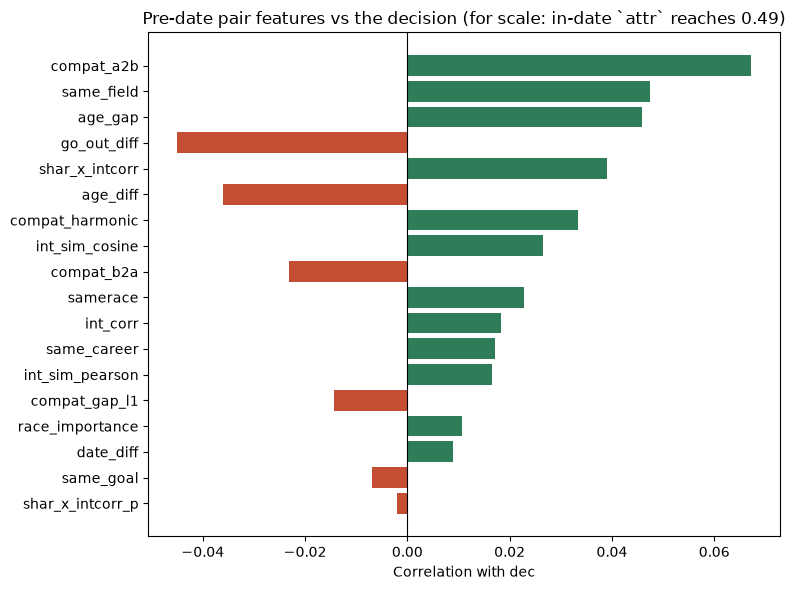

Strongest pre-date pair feature: |r| = 0.067
For comparison, the in-date `attr` rating reaches |r| = 0.487


In [9]:
signal = pd.DataFrame({
    "corr_with_dec":   [features[f].corr(features["dec"]) for f in dyadic_and_compat],
    "corr_with_match": [features[f].corr(features["match"]) for f in dyadic_and_compat],
}, index=dyadic_and_compat).sort_values("corr_with_dec", key=abs, ascending=False)
display(signal)

order = signal["corr_with_dec"].abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(order)), signal.loc[order, "corr_with_dec"],
        color=[RED if v < 0 else GREEN for v in signal.loc[order, "corr_with_dec"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_title("Pre-date pair features vs the decision (for scale: in-date `attr` reaches 0.49)")
ax.set_xlabel("Correlation with dec")
plt.tight_layout(); plt.show()

print(f"Strongest pre-date pair feature: |r| = {signal['corr_with_dec'].abs().max():.3f}")
print(f"For comparison, the in-date `attr` rating reaches |r| = {abs(raw['attr'].corr(raw['dec'])):.3f}")

**What to notice — including one result that validates the join.** The whole block is weak: the
strongest feature is `compat_a2b` at r = **0.067** against `dec`, against **0.487** for the in-date
attractiveness rating the protocol forbids. This is the pre-date constraint doing exactly what the
EDA said it would — it removes the strong signals and leaves weak ones that only a model combining
them can use.

**The two compatibility directions behave the way they should, which is a correctness check on the
join.** `compat_a2b` asks *does this partner match my stated criteria*, and it correlates
**+0.067** with **my** decision. Its mirror `compat_b2a` asks *do I match their criteria*, and it
is essentially unrelated to my decision (**−0.023**) — as it must be: my criteria drive my choice,
theirs drive theirs. Against the symmetric `match` label the two are equal (**+0.037** each),
because a mutual yes needs both directions to work. Had the join been swapped, these signs would
have come out the other way round.

Two caveats against reading the table too literally. A linear correlation is the wrong lens on an
interaction like `race_importance`, whose entire behaviour is conditional (EDA §8.1). And a weak
*marginal* correlation is not a useless feature: the EDA's feasibility probe (§15.3) reached
AUC ≈ 0.59 on `dec` with these combined. That is the number to beat, not 0.5.

## 10. The leakage guard — enforced in code, not in a comment

Evaluation rigour is the largest block in the grading rubric, and the single most expensive mistake
available here is putting an in-date column into a "pre-date" feature set. A comment saying we did
not is worth nothing; an assertion that fails loudly is worth something.

`sd_features.BANNED_LEAKY` names every forbidden column, in four groups:

| Group | Columns | Why |
|---|---|---|
| In-date scorecard | `attr`, `sinc`, `intel`, `fun`, `amb`, `shar`, `like`, `prob` | Recorded during the date, at the same moment as the decision. `like` (r = 0.51) is close to a restatement of `dec` itself |
| The partner's in-date block | `attr_o … prob_o`, `like_o`, `met_o` | Same thing from the other side |
| Labels and label-adjacent | `dec_o`, `met` | `dec_o` is the *reverse direction's label*. It is exported for that purpose and must never be an input |
| Excluded by decision | `condtn`; `expnum`, `mn_sat`, `tuition`, `income` | `condtn` is a designed manipulation constant within a wave — it cannot reorder anything *inside* a fold (EDA §10.1). The other four are 49–77% missing, non-randomly |

Plus every column ending in `_s`, `_2` or `_3` — the mid-event and follow-up surveys, which are
recorded after the decisions they would be predicting.

In [10]:
violations = sf.leakage_report()
banned_in_table = [c for c in features.columns
                   if c in set(sf.BANNED_LEAKY) or c.endswith(sf.BANNED_SUFFIXES)]

print(f"Columns in FEATURES_ALL that are banned:            {len(violations)}")
print(f"Banned columns present in the exported table:       {banned_in_table}")
print("   (`dec_o` is exported deliberately -- it is the reverse direction's LABEL, and it is")
print("    excluded from FEATURES_ALL, so no model can pick it up by accident.)")

assert violations.empty, f"LEAKAGE: {violations}"
assert not (set(sf.FEATURES_ALL) & set(sf.BANNED_LEAKY)), "LEAKAGE in FEATURES_ALL"
print()
print(f"PASS -- {len(sf.FEATURES_ALL)} features, none of them banned.")
print(f"`order` is exported but held out of FEATURES_ALL: pre-date, but a scheduling artefact")
print(f"(|r| = {abs(raw['order'].corr(raw['dec'])):.3f}), not a preference signal.")

Columns in FEATURES_ALL that are banned:            0
Banned columns present in the exported table:       ['dec_o']
   (`dec_o` is exported deliberately -- it is the reverse direction's LABEL, and it is
    excluded from FEATURES_ALL, so no model can pick it up by accident.)

PASS -- 95 features, none of them banned.
`order` is exported but held out of FEATURES_ALL: pre-date, but a scheduling artefact
(|r| = 0.032), not a preference signal.


## 11. The behavioural block — why the strongest features are not in the table

This is the most consequential decision in this notebook, and the one most likely to be questioned,
so it is demonstrated rather than asserted.

Person-level behavioural rates — how often someone says yes (`selectivity`), how often they are
said yes to (`desirability`) — are by far the strongest pre-date signals in the dataset. The EDA
measured leave-one-out selectivity at |r| ≈ 0.40 against `dec` and partner desirability at ≈ 0.36
(§13.3), an order of magnitude above every profile feature in Section 9.

They are still not in the feature table, because of how this dataset is shaped: **each participant
attends exactly one wave.** Hold that wave out, and the person has no dates left in the training
data at all — so every behavioural feature falls back to its cold-start default, and a constant
cannot reorder a ranked list.

`add_behavioural_features(train_df, apply_df)` is kept in the module anyway, estimated train-only
with shrinkage (m = 20, the interior optimum of split-half reliability, EDA §13.3), for two jobs
that still need it:

1. the training-side **desirability target** for the re-specified popularity baseline **Z**
   ("predicted desirability from profile features", EDA §15.1);
2. a deliberately-labelled **optimistic within-fold reference**.

Note it takes *raw* date rows, not the feature table — `avg_attr_received` comes from `attr_o`,
which the feature table excludes as in-date leakage.

The cell below runs it across all 21 folds and measures the fallback rate.

In [11]:
rows = []
for w in sorted(raw["wave"].unique()):
    train_rows = raw[raw["wave"] != w]
    apply_rows = raw[(raw["wave"] == w) & raw["pid"].notna()]
    scored = sf.add_behavioural_features(train_rows, apply_rows)
    rows.append({
        "wave": w,
        "test_rows": len(scored),
        "pct_self_cold_start": scored["behav_cold_start"].mean(),
        "pct_partner_cold_start": scored["behav_cold_start_p"].mean(),
        "distinct_desirability_values": scored["desirability"].nunique(),
    })
fallback = pd.DataFrame(rows).set_index("wave")
display(fallback)

print(f"Mean share of test rows receiving the cold-start fallback: "
      f"{fallback['pct_self_cold_start'].mean():.1%} (self), "
      f"{fallback['pct_partner_cold_start'].mean():.1%} (partner)")
print(f"Folds where every scored person is a constant: "
      f"{int((fallback['distinct_desirability_values'] == 1).sum())} of {len(fallback)}")

,test_rows,pct_self_cold_start,pct_partner_cold_start,distinct_desirability_values
wave,,,,
1,200,1.000,1.000,1
2,608,1.000,1.000,1
3,200,1.000,1.000,1
4,648,1.000,1.000,1
5,180,1.000,1.000,1
6,50,1.000,1.000,1
7,512,1.000,1.000,1
8,200,1.000,1.000,1
9,800,1.000,1.000,1


Mean share of test rows receiving the cold-start fallback: 100.0% (self), 100.0% (partner)
Folds where every scored person is a constant: 21 of 21


**What to notice:** **100% of test rows in all 21 folds** receive the cold-start fallback, and the
`desirability` column takes exactly **one distinct value** on every held-out wave. That is not a
weak feature — it is a column of the same number repeated, which contributes precisely nothing to
a ranking and would only add noise to a model's coefficient estimates.

This is why the behavioural family is absent from the export, and the absence is a *decision*, not
an oversight. Anyone who reintroduces it should re-run this cell first.

> **Hand-off note for the baseline.** The same result re-specifies baseline **Z**. "Rank each
> partner by how often they received a yes" is not computable for a held-out participant, because
> nobody has said yes to them in the training data. The EDA's recommendation (§15.1) is *predicted*
> desirability: train a model on the training waves that predicts `desirability` from profile
> features, then apply it to the cold test participants. `add_behavioural_features` produces the
> training-side target that model needs.

## 12. Fold-aware preprocessing — why the export is deliberately unscaled

A scaler fitted on the whole table has already seen the held-out wave's extremes and medians. It is
the same leak as fitting a model on test data, in a quieter form, and it is invisible in the
results — the numbers just come out slightly too good (EDA §14.1).

So the exported CSV holds **raw** engineered values, and `fit_preprocessor(train_df)` returns a
transformer fitted on the training waves only. The split between what is fitted and what is not
matters, and is deliberate:

| Treatment | Columns | Fitted on data? |
|---|---|---|
| Clipping to the documented range | all 1–10 ratings and interests, the 1–7 ordinals | **No** — done once, in `build_person_table` |
| Min–max onto the **documented** range: `(x−1)/9`, `(x−1)/6` | importance, expectation, interests, self-ratings, frequency ordinals | **No** — the constants come from the data key, so a value means the same thing in every fold and nothing can leak |
| Min–max onto the **documented** range: `x/10` | `race_importance` | **No** — same reasoning, but it needs its own divisor: it is `imprace × samerace`, so 0 is a real value (a different-race pair, 59.5% of rows) and `(x−1)/9` would map it to −0.111 |
| Z-scoring | `age`, `age_diff`, `age_gap`, the frequency diffs, the `compat_*` family, the `int_sim_*` family | **Yes — training waves only** |
| Median imputation | all numeric | **Yes — training waves only** (`impute=False` for models that handle `NaN`, such as `HistGradientBoosting`) |
| One-hot with **fixed** category lists | `race`, `field_cd`, `career_c`, `goal`, both sides | **No** — categories come from the data key, so every fold produces an identical column layout |
| Left alone | preference shares (already sum to 1), 0/1 indicators, `int_corr` (already [−1, 1]) | — |

The cell below proves the distinction rather than describing it: fit on 20 waves, fit on all 21,
and compare.

In [12]:
train = features[features["wave"] != 1]
test  = features[features["wave"] == 1]

prep = sf.fit_preprocessor(train)                 # <- training waves ONLY
X_train = sf.transform(prep, train)
X_test  = sf.transform(prep, test)

print(f"X_train {X_train.shape}   X_test {X_test.shape}")
print(f"Identical column layout: {list(X_train.columns) == list(X_test.columns)}")
print(f"Any NaN left after imputation: {bool(X_train.isna().any().any() or X_test.isna().any().any())}")

# The demonstration: does it actually matter that we fitted on a subset?
prep_leaky = sf.fit_preprocessor(features)        # the WRONG way, for comparison only
scaler_honest = prep.named_transformers_["standardise"].named_steps["scale"]
scaler_leaky  = prep_leaky.named_transformers_["standardise"].named_steps["scale"]

comparison = pd.DataFrame({
    "fitted_on_20_waves": scaler_honest.mean_,
    "fitted_on_all_21":   scaler_leaky.mean_,
}, index=sf._STANDARDISE)
comparison["difference"] = comparison["fitted_on_20_waves"] - comparison["fitted_on_all_21"]
display(comparison)

print(f"Columns whose scaling changes when the held-out wave is included: "
      f"{int((comparison['difference'].abs() > 1e-9).sum())} of {len(comparison)}")
print("The documented-range min-max columns are identical either way, by construction --")
print("that is the point of scaling to the documented range rather than the observed one.")

X_train (8168, 181)   X_test (200, 181)
Identical column layout: True
Any NaN left after imputation: False


,fitted_on_20_waves,fitted_on_all_21,difference
age,26.409,26.361,0.048
age_p,26.409,26.361,0.048
age_diff,3.664,3.644,0.020
age_gap,0.000,0.000,0.000
go_out_diff,1.138,1.120,0.018
date_diff,1.588,1.599,-0.011
int_sim_pearson,0.222,0.219,0.003
int_sim_cosine,0.890,0.889,0.000
compat_a2b,7.828,7.819,0.009
compat_b2a,7.828,7.819,0.009


Columns whose scaling changes when the held-out wave is included: 13 of 14
The documented-range min-max columns are identical either way, by construction --
that is the point of scaling to the documented range rather than the observed one.


**What to notice:** every z-scored column shifts when the held-out wave is folded into the fit. The
shifts are small — a few hundredths on `age` — and that is exactly what makes this leak dangerous:
too small to notice in a results table, large enough to be indefensible when someone asks how the
scaler was fitted.

The min–max columns, by contrast, are bit-identical whichever set they are fitted on, because they
are not fitted at all. Scaling to the *documented* range instead of the observed one costs nothing
and removes a whole class of leak.

## 13. Verification — ten checks that must pass

Everything above is only as good as its weakest assumption. This section re-tests all of them in one
place, so a future change that breaks something fails here rather than in someone's results table.

The mirror-symmetry check (number 5) is the important one. It is the test that catches a swapped
join — the single easiest bug to introduce in a pairwise feature table, and one that produces a
perfectly plausible-looking output. It works because every encounter is present from both sides:
`compat_a2b` on row `(a, b)` must equal `compat_b2a` on row `(b, a)`, and the signed `age_gap` must
flip sign.

In [13]:
checks = []


def check(name, passed, detail=""):
    checks.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})


# 1. shape and key completeness
check("1. Shape is 8,368 x 102", features.shape == (8368, 102), f"{features.shape}")
key_nulls = int(features[["iid", "pid", "wave", "gender", "dec", "match"]].isna().sum().sum())
check("2. Keys and labels have no nulls", key_nulls == 0, f"{key_nulls} nulls")

# 3. no column is entirely empty
all_nan = [c for c in features.columns if features[c].isna().all()]
check("3. No engineered column is all-NaN", not all_nan, f"{all_nan}")

# 4. leakage guard
check("4. No banned column in FEATURES_ALL", sf.leakage_report().empty,
      f"{len(sf.FEATURES_ALL)} features checked")

# 5. mirror symmetry -- the swapped-join detector
by_pair = features.set_index(["iid", "pid"])
mirrored = features.assign(_a=features["pid"], _b=features["iid"]).set_index(["_a", "_b"])
shared = by_pair.index.intersection(mirrored.index)
lhs, rhs = by_pair.loc[shared], mirrored.loc[shared]

symmetric = {"match": "match", "samerace": "samerace", "int_corr": "int_corr",
             "age_diff": "age_diff", "compat_harmonic": "compat_harmonic",
             "compat_a2b": "compat_b2a"}
worst_sym = max(float((lhs[a] - rhs[b]).abs().max()) for a, b in symmetric.items())
check("5. Mirror symmetry (incl. compat_a2b == compat_b2a on the mirror)", worst_sym < 1e-9,
      f"max deviation {worst_sym:.2e} over {len(shared):,} pairs")

worst_anti = float((lhs["age_gap"] + rhs["age_gap"]).abs().max())
check("6. Signed age_gap is antisymmetric", worst_anti < 1e-9, f"max deviation {worst_anti:.2e}")

# 7. preference shares
pref_complete = features[sf.PREF].notna().all(axis=1)
worst_share = float((features.loc[pref_complete, sf.PREF].sum(axis=1) - 1).abs().max())
check("7. Preference shares sum to 1", worst_share < 1e-9,
      f"max deviation {worst_share:.2e} on {int(pref_complete.sum()):,} complete rows")

# 8. behavioural features are 100% fallback -- re-check, do not trust Section 11's prose
check("8. Behavioural features are 100% cold-start on every fold",
      bool((fallback["pct_self_cold_start"] == 1.0).all()),
      f"{len(fallback)} folds, all constant")

# 9. preprocessor is genuinely fitted on the training subset
check("9. Preprocessor scaling differs when fitted train-only",
      bool((comparison["difference"].abs() > 1e-9).any()),
      f"{int((comparison['difference'].abs() > 1e-9).sum())} columns shift")

# 10. every feature actually reaches the design matrix
#     `remainder="drop"` deletes any column no block claims -- silently, which is how
#     `race_importance` was absent from every model while being declared, documented and counted.
coverage = sf.coverage_report()
check("10. Every feature in FEATURES_ALL reaches the design matrix", coverage.empty,
      f"{len(sf.FEATURES_ALL)} features, {len(coverage)} unassigned")

results = pd.DataFrame(checks)
display(results)

n_failed = int((results["result"] == "FAIL").sum())
print(f"{len(results) - n_failed} of {len(results)} checks passed.")
assert n_failed == 0, results[results["result"] == "FAIL"]

,check,result,detail
0,"1. Shape is 8,368 x 102",PASS,"(8368, 102)"
1,2. Keys and labels have no nulls,PASS,0 nulls
2,3. No engineered column is all-NaN,PASS,[]
3,4. No banned column in FEATURES_ALL,PASS,95 features checked
4,5. Mirror symmetry (incl. compat_a2b == compat...,PASS,"max deviation 0.00e+00 over 8,368 pairs"
5,6. Signed age_gap is antisymmetric,PASS,max deviation 0.00e+00
6,7. Preference shares sum to 1,PASS,"max deviation 2.22e-16 on 8,249 complete rows"
7,8. Behavioural features are 100% cold-start on...,PASS,"21 folds, all constant"
8,9. Preprocessor scaling differs when fitted tr...,PASS,13 columns shift
9,10. Every feature in FEATURES_ALL reaches the ...,PASS,"95 features, 0 unassigned"


10 of 10 checks passed.


Coverage is the other thing the next person needs to know up front: how much of the table is
actually populated, block by block. Nothing here is imputed — the gaps travel to the export as
`NaN` and are filled inside the fold, or not at all for a model that handles them natively.

In [14]:
missing = pd.DataFrame({
    "nan_fraction": features[sf.FEATURES_ALL].isna().mean(),
}).sort_values("nan_fraction", ascending=False)

print(f"Rows complete on every one of the {len(sf.FEATURES_ALL)} features: "
      f"{features[sf.FEATURES_ALL].notna().all(axis=1).mean():.1%}")
print(f"Features with no missing values at all: "
      f"{int((missing['nan_fraction'] == 0).sum())} of {len(missing)}")
print(f"Worst-populated feature: {missing.index[0]} ({missing.iloc[0, 0]:.1%} missing)")
display(missing.head(10).T)

Rows complete on every one of the 95 features: 94.2%
Features with no missing values at all: 2 of 95
Worst-populated feature: compat_harmonic (3.5% missing)


,compat_harmonic,same_career,compat_a2b,compat_gap_l1,compat_b2a,shar_x_intcorr_p,shar_x_intcorr,date_diff,age_gap,age_diff
nan_fraction,0.035,0.033,0.027,0.027,0.027,0.024,0.024,0.023,0.022,0.022


**What to notice:** 94.2% of rows are complete on all 95 features, and the worst column
(`compat_harmonic`, which needs both people's preference *and* self-rating blocks) is missing
3.5%. That is a small imputation budget, and it is concentrated in a handful of participants who
skipped part of the signup survey rather than spread thinly across everyone — so a median
imputation inside the fold affects few rows and distorts nothing systematically.

## 14. The data dictionary and the export

The dictionary is the actual hand-off artefact. A colleague should be able to answer "what is
`compat_b2a` and can I trust it?" without reading `sd_features.py` or this notebook.

It is generated from a specification inside the module and then **checked against the exported
table**, so it cannot silently fall out of date — a dictionary that drifts is worse than none.

The second cell below is where the files are actually written, and it is the **only** place in the
project that produces them. `sf.export()` creates `Data/features/` if it is missing and writes
`speed_dating_features.csv` and `feature_dictionary.csv` into it, adding a Parquet copy when
`pyarrow` is installed; the table is then reloaded from disk to confirm the round trip. Re-running
this notebook overwrites all of them, so any change to a feature definition has to be followed by
committing the refreshed files. The two CSVs are under version control — `load_features()` works
from a fresh clone with nothing else run first — while the Parquet copy is deliberately left out,
being a byte-for-byte duplicate of the CSV.

In [15]:
dictionary = sf.build_dictionary(features)

assert set(dictionary["column"]) == set(features.columns), "dictionary and table disagree"
print(f"Dictionary covers all {len(dictionary)} exported columns.")
display(dictionary.groupby("block").agg(
    columns=("column", "size"),
    in_features_all=("in_features_all", "sum"),
    mean_nan_fraction=("nan_fraction", "mean"),
))

# The pair-level features in full -- the ones a reader is most likely to need explained.
pd.set_option("display.max_colwidth", 90)
display(dictionary[dictionary["block"].isin(["dyadic", "compatibility", "label", "key",
                                             "key / feature", "key / diagnostic"])]
        [["column", "block", "definition", "documented_range", "in_features_all"]]
        .reset_index(drop=True))
pd.reset_option("display.max_colwidth")

Dictionary covers all 102 exported columns.


,columns,in_features_all,mean_nan_fraction
block,,,
compatibility,6,6,0.027
dyadic,12,12,0.019
interest,34,34,0.009
key,3,0,0.000
key / diagnostic,1,0,0.000
key / feature,1,1,0.000
label,3,0,0.000
profile,20,20,0.011
self-rating,10,10,0.013


,column,block,definition,documented_range,in_features_all
0,iid,key,"Participant id, unique across the study",-,False
1,pid,key,Partner's iid for this date -- who they met,-,False
2,wave,key,Session 1-21; the unit the CV splits on,1-21,False
3,gender,key / feature,"0 = female, 1 = male (also a feature: the yes-rate gap is 10.9pp)",0/1,True
4,order,key / diagnostic,Position of this date in the night. Pre-date but a scheduling artefact (|r| = 0.03); e...,1-22,False
5,dec,label,This participant's yes/no about the partner -- the DIRECTIONAL training target,0/1,False
6,dec_o,label,"The partner's yes/no about this participant, i.e. the reverse direction's label. LABEL...",0/1,False
7,match,label,1 iff both said yes -- the symmetric relevance label,0/1,False
8,age_diff,dyadic,Absolute age difference,0+,True
9,age_gap,dyadic,Signed age difference (decider minus partner),+/-,True


In [16]:
written = sf.export(features, dictionary)
for path in written:
    print(f"wrote {path}  ({path.stat().st_size / 1e6:.2f} MB)")

# Round-trip: the CSV must reload to the same thing.
reloaded = sf.load_features()
print(f"\nReloaded {reloaded.shape[0]:,} x {reloaded.shape[1]} -- matches: "
      f"{reloaded.shape == features.shape and list(reloaded.columns) == list(features.columns)}")

wrote Data\features\speed_dating_features.csv  (4.44 MB)
wrote Data\features\speed_dating_features.parquet  (0.51 MB)
wrote Data\features\feature_dictionary.csv  (0.01 MB)

Reloaded 8,368 x 102 -- matches: True


**What to notice:** the parquet file is written when `pyarrow` is available, but `*.parquet` is
gitignored — **the CSV is the committed artefact**. Anyone cloning the repo gets the CSV; the
parquet is a local convenience.

## 15. Hand-off — how to use this table

*Written for whoever builds the baseline, X₁, X₂ or the evaluation. You do not need to have read
the EDA or the rest of this notebook.*

### The four lines that matter

```python
from sd_features import load_features, fit_preprocessor, transform, FEATURES_ALL

feat = load_features()                     # 8,368 directed encounters, raw engineered features

for w in sorted(feat["wave"].unique()):    # the CV loop is YOURS -- 21 leave-one-wave-out folds
    train, test = feat[feat["wave"] != w], feat[feat["wave"] == w]
    prep = fit_preprocessor(train)         # fitted on training waves ONLY -- never on `feat`
    X_tr, X_te = transform(prep, train), transform(prep, test)
    y_tr, y_te = train["dec"], test["dec"]         # or "match" for the symmetric target
```

Pass `fit_preprocessor(train, impute=False)` if your model handles `NaN` natively
(`HistGradientBoostingClassifier` does); otherwise gaps are median-imputed from the training waves.

### Five things that will bite you if you skip them

1. **The features are raw on purpose.** Fit the preprocessor inside the loop. Fitting it on the
   full table leaks the held-out wave's extremes into the scaling — small, invisible, and
   indefensible when asked.
2. **`dec` is the directional target; `match` is the relevance label.** `dec_o` is exported because
   it is the *reverse direction's* label — never feed it to a model. It is already excluded from
   `FEATURES_ALL`; use that list rather than "every column except the keys".
3. **One row is one direction.** To score the pair A↔B you need both rows, `(a,b)` and `(b,a)`.
   All 8,368 mirrors are present, so a merge on `left_on=["iid","pid"], right_on=["pid","iid"]`
   always finds its partner. `compat_harmonic` is already the symmetric combination if you want a
   ready-made reciprocal score.
4. **Behavioural features are absent by design, not by omission** (Section 11): they are constant
   on every test fold. Baseline **Z** does not use them: its desirability target is
   `wilson_desirability(train_raw, apply_raw)` on the *raw* rows (see
   `03_Baseline_Desirability_Model.ipynb`). `add_behavioural_features` survives only as an
   optimistic within-fold reference (Section 11).
5. **Categorical codes are one-hot encoded with fixed category lists.** Do not re-derive categories
   from your fold, or your feature matrix will change width between folds.

### What is in `FEATURES_ALL` (95 columns)

| Group | Count | Constant to use |
|---|---|---|
| Profile, both sides (numeric + categorical codes) | 20 | `FEATURES_PROFILE` |
| Stated-preference shares, both sides | 12 | `FEATURES_PREF` |
| Self-ratings, both sides | 10 | `FEATURES_SELFRATE` |
| Interests, both sides | 34 | `FEATURES_INTERESTS` |
| Dyadic comparisons | 12 | `FEATURES_DYADIC` |
| Compatibility (both directions + harmonic) | 6 | `FEATURES_COMPAT` |
| `gender` | 1 | — |

For **X₁** (gender-asymmetric clustering) the deck's design clusters men on their self-ratings
(`FEATURES_SELFRATE`, the un-suffixed half) and women on their stated preferences (`FEATURES_PREF`,
un-suffixed). Both are one row per person: de-duplicate on `iid` first.

For **X₂** (factorization machine) the pairwise vector is `FEATURES_ALL` as it stands — both
people's attributes and stated preferences are already on the row.

### Known limitations, inherited and measured

- The pre-date block is **weak**: the strongest single feature reaches |r| = 0.067 against `dec`,
  and the EDA's generously-specified feasibility probe reached AUC ≈ 0.59 (`dec`) and 0.56
  (`match`) under the real protocol. Improvements will be small, so **report the standard deviation
  across the 21 folds**, not just the mean.
- The 21 folds are **not equivalent**: per-wave match rates run 8.3% to 31.0%, and part of that
  spread is the `condtn` experimental manipulation, which is constant within a wave.
- 18.0% of users have **no matching partner at all**, so their MRR is undefined and their NDCG is
  convention-dependent. Decide explicitly whether to skip or zero-score them, and say which.
- `int_corr` and our recomputed `int_sim_pearson` are **not interchangeable** (Section 8).

## 16. Summary

1. **8,368 directed encounters × 102 columns** exported, from 551 participants across 21 waves.
   Ten raw rows with no `pid` are dropped; every remaining row has its mirror.
2. **95 features in six blocks**, all strictly pre-date, enforced by an executable leakage guard
   rather than a comment.
3. **The compatibility features are the reciprocal core**: `compat_a2b`, `compat_b2a` and their
   harmonic mean, built from stated preference shares against the partner's *self-ratings* — the
   only formulation that survives both the pre-date rule and the cold start.
4. **Behavioural features are excluded on measured grounds**: 100% cold-start fallback on all 21
   folds, one distinct value per held-out wave.
5. **Nothing is scaled in the export.** `fit_preprocessor(train)` does that inside the fold, with
   documented-range min–max where no fitting is needed and train-only z-scoring where it is.
6. **94.2% of rows are complete** on every feature; the worst column is 2.5% missing, and nothing
   is imputed before the fold.

Next steps belong to other people: baseline **Z** (predicted desirability,
`03_Baseline_Desirability_Model.ipynb`), **X₁** (`04_X1_Clustering.ipynb`), **X₂**
(`04_Speed_Dating_Factorization_Machine.ipynb`) and the 21-fold evaluation. Section 15 is written for them.